# 13 — Target relativo ao prazo: baseline, regressão e survival

## Pergunta de negócio

> **Quanto tempo a obra tende a consumir em relação ao prazo original?**

Em vez de prever "dias de atraso", prevemos um **target relativo**:

$$\text{tempo\_relativo} = \frac{\text{duração observada}}{\text{prazo original}}$$

- `1,00` → terminou exatamente no prazo original
- `1,30` → consumiu 130% do prazo original (30% a mais)

Assim, uma obra de 6 meses e outra de 2 anos ficam na **mesma escala**.

## Por que dividir pelo prazo **original** (e não pelo vigente)?

O prazo original é conhecido no dia da OS e **nunca muda**. O prazo vigente muda a cada aditivo — se ele fosse o
denominador, a régua do target mudaria no meio da obra.

Por isso o prazo vigente entra só no final, como **linha de corte** para medir risco:
se `tempo_relativo = 1,30` e o prazo vigente equivale a `1,50 × original`, a obra ainda está dentro do contrato.

## Mapa do notebook

| Etapa | O que faz |
|---|---|
| 0 | Configuração (tudo que se ajusta fica aqui) |
| 1 | Carrega a base de contratos |
| 2 | Classifica contratos e constrói o target |
| 3 | Monta a validação temporal (sem olhar o futuro) |
| 4 | Define as métricas |
| 5 | Treina e avalia os 3 modelos com **o mesmo loop** |
| 6 | Compara os modelos e escolhe o vencedor |
| 7 | Ajusta o modelo final e calcula risco dos contratos em andamento |
| 8 | Resumo e exportação |

| Modelo | Usa contratos em andamento? | Papel |
|---|:---:|---|
| Baseline mediana | Não | régua mínima — qualquer modelo tem que ganhar dele |
| GammaRegressor | Não | regressão tradicional para target positivo e assimétrico |
| AFT Log-Normal | **Sim** (como censurados) | modelo de sobrevivência — candidato principal |

# Etapa 0 — Configuração

Todos os parâmetros ajustáveis ficam nesta célula. Para rodar uma nova versão (ex.: nova data de corte,
novas features), **só esta célula precisa mudar**.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.stats import norm
from sklearn.impute import SimpleImputer
from sklearn.linear_model import GammaRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

# Data "de hoje": contratos sem conclusão até aqui são tratados como censurados.
DATA_CORTE = pd.Timestamp("2026-10-14")

ARQUIVO_CONTRATOS = "contratos_com_conclusao_andamento.csv"

FEATURES = ["log_prazo_original"]

# Força da regularização testada para Gamma e AFT (o baseline não tem esse parâmetro).
ALPHAS = [0.1, 1.0, 10.0, 100.0]

# Validação temporal: cada fold valida 7 contratos consecutivos (ordem de data_os),
# começando nestas posições. Folds com menos de 5 contratos são descartados.
FOLD_STARTS = [28, 35, 42, 49]
TAMANHO_FOLD = 7
MIN_FOLD = 5

# Etapa 1 — Carregar a base

A função procura `data/raw/<arquivo>` subindo a partir da pasta atual (funciona rodando o notebook de qualquer
subpasta do projeto). As saídas vão para `data/outputs/13_target_relativo`, ao lado de `data/raw`.

In [2]:
def localizar(nome):
    """Procura data/raw/<nome> na pasta atual e nas pastas-pai."""
    atual = Path.cwd().resolve()
    pastas = [raiz / "data" / "raw" for raiz in (atual, *atual.parents)]
    for pasta in pastas:
        if (pasta / nome).is_file():
            return (pasta / nome).resolve()
    raise FileNotFoundError(
        f"'{nome}' não encontrado. Pastas verificadas:\n  " + "\n  ".join(map(str, pastas))
    )


PATH_CONTRATOS = localizar(ARQUIVO_CONTRATOS)
OUTPUT_DIR = PATH_CONTRATOS.parent.parent / "outputs" / "13_target_relativo"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

contratos = pd.read_csv(PATH_CONTRATOS, encoding="utf-8-sig", low_memory=False)

print("Arquivo:", PATH_CONTRATOS)
print("Saídas: ", OUTPUT_DIR)
print("Shape:  ", contratos.shape)

Arquivo: C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\raw\contratos_com_conclusao_andamento.csv
Saídas:  C:\Users\Gabriel\OneDrive\Documentos\projeto_previsao_termino_obras\data\outputs\13_target_relativo
Shape:   (64, 10)


# Etapa 2 — Classificar contratos e construir o target

### 2.1 Três grupos (nenhum contrato é descartado)

| Grupo | Regra | Como entra no modelo |
|---|---|---|
| `CONCLUIDO_COM_TARGET` | tem data de conclusão **e** atraso definitivo | evento (desfecho conhecido) |
| `SUSPENSO_PARALISADO` | status contém SUSPENSO ou PARALISADO | fica na base, **fora** do ajuste |
| `EM_ANDAMENTO_CENSURADO` | todo o resto | censurado (sabemos só que "ainda não acabou") |


### 2.2 Target

- Concluído: `tempo_observado = data_conclusão − data_OS`
- Censurado: `tempo_observado = DATA_CORTE − data_OS` (tempo *mínimo* que a obra vai durar)
- `tempo_relativo_observado = tempo_observado / prazo_original`
- `evento_conclusao` = 1 se concluído, 0 se censurado

### 2.3 Limite vigente (para medir risco no final)

`limite_relativo_vigente = prazo_vigente_atual / prazo_original`


In [3]:
df = contratos.copy()

# Datas em formato datetime (valores inválidos viram NaT).
for col in ["data_os", "data_termino_original", "data_termino_vigente_final", "data_conclusao_definitiva"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# --- 2.1 Grupos -------------------------------------------------------------
concluido = df["data_conclusao_definitiva"].notna() & df["atraso_definitivo_dias"].notna()
suspenso = df["status_final_controle"].astype(str).str.upper().str.contains("SUSPENSO|PARALISADO")

df["grupo_modelagem"] = np.select(
    [concluido, suspenso],                          # ordem = prioridade
    ["CONCLUIDO_COM_TARGET", "SUSPENSO_PARALISADO"],
    default="EM_ANDAMENTO_CENSURADO",
)
df["evento_conclusao"] = concluido.astype(int)
df["flag_apto_modelagem"] = (~df["grupo_modelagem"].eq("SUSPENSO_PARALISADO")).astype(int)

# --- 2.2 Target relativo -----------------------------------------------------
df["data_fim_observacao"] = df["data_conclusao_definitiva"].where(concluido, DATA_CORTE)
df["tempo_observado_dias"] = (df["data_fim_observacao"] - df["data_os"]).dt.days.clip(lower=1)
df["tempo_relativo_observado"] = df["tempo_observado_dias"] / df["prazo_original_dias"]

# Feature: log do prazo (reduz a assimetria entre obras curtas e longas).
df["log_prazo_original"] = np.log1p(df["prazo_original_dias"])

# --- 2.3 Limite vigente ------------------------------------------------------
prazo_vigente = (df["data_termino_vigente_final"] - df["data_os"]).dt.days
df["prazo_vigente_atual_dias"] = prazo_vigente.where(prazo_vigente > 0, df["prazo_original_dias"])
df["limite_relativo_vigente"] = df["prazo_vigente_atual_dias"] / df["prazo_original_dias"]

# --- Checagens de sanidade ----------------------------------------------------
assert len(df) == 64, f"Esperados 64 contratos, encontrados {len(df)}"
assert (df.loc[df["flag_apto_modelagem"].eq(1), "prazo_original_dias"] > 0).all(), "prazo_original inválido"

resumo_grupos = df["grupo_modelagem"].value_counts().rename_axis("grupo").reset_index(name="contratos")
display(resumo_grupos)
display(df[["id_contrato", "grupo_modelagem", "prazo_original_dias", "tempo_observado_dias",
            "tempo_relativo_observado", "evento_conclusao", "limite_relativo_vigente"]].head(10))

,grupo,contratos
0,CONCLUIDO_COM_TARGET,50
1,EM_ANDAMENTO_CENSURADO,13
2,SUSPENSO_PARALISADO,1


,id_contrato,grupo_modelagem,prazo_original_dias,tempo_observado_dias,tempo_relativo_observado,evento_conclusao,limite_relativo_vigente
0,11,CONCLUIDO_COM_TARGET,150,175,1.166667,1,1.000000
1,12,CONCLUIDO_COM_TARGET,90,229,2.544444,1,1.000000
2,18,CONCLUIDO_COM_TARGET,120,150,1.250000,1,1.250000
3,29,CONCLUIDO_COM_TARGET,240,524,2.183333,1,1.741667
4,30,CONCLUIDO_COM_TARGET,90,90,1.000000,1,1.000000
5,31,CONCLUIDO_COM_TARGET,120,210,1.750000,1,1.500000
6,32,CONCLUIDO_COM_TARGET,90,150,1.666667,1,1.666667
7,33,CONCLUIDO_COM_TARGET,660,750,1.136364,1,1.136364
8,46,CONCLUIDO_COM_TARGET,180,298,1.655556,1,1.500000
9,47,CONCLUIDO_COM_TARGET,180,222,1.233333,1,1.166667


count    50.000
mean      1.727
std       1.030
min       0.556
25%       1.159
50%       1.441
75%       1.903
max       7.333
Name: tempo_relativo_observado, dtype: float64


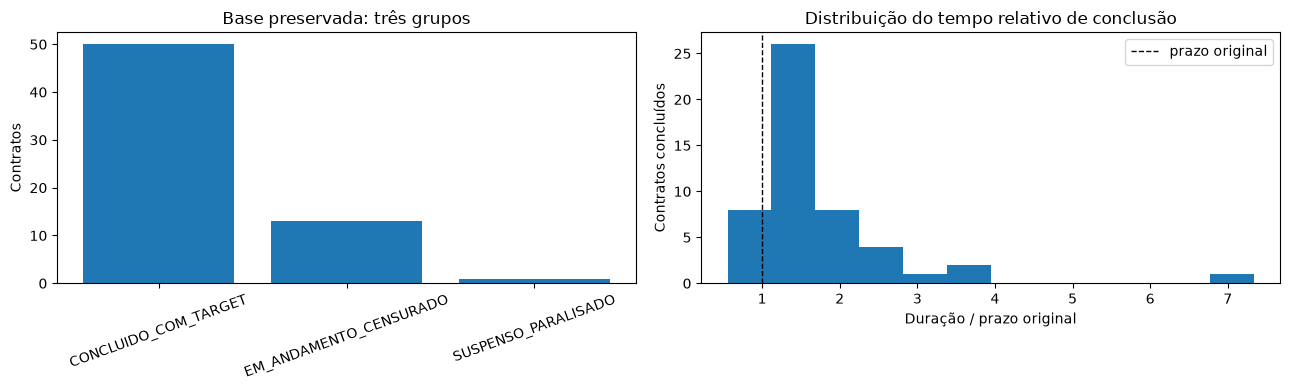

In [4]:
# Visão rápida: tamanho dos grupos e distribuição do target nos concluídos.
concluidos = df[df["evento_conclusao"].eq(1)]
print(concluidos["tempo_relativo_observado"].describe().round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.bar(resumo_grupos["grupo"], resumo_grupos["contratos"])
ax1.set_ylabel("Contratos")
ax1.set_title("Base preservada: três grupos")
ax1.tick_params(axis="x", rotation=20)

ax2.hist(concluidos["tempo_relativo_observado"], bins=12)
ax2.axvline(1.0, linestyle="--", linewidth=1, color="k", label="prazo original")
ax2.set_xlabel("Duração / prazo original")
ax2.set_ylabel("Contratos concluídos")
ax2.set_title("Distribuição do tempo relativo de conclusão")
ax2.legend()

plt.tight_layout()
plt.show()

# Etapa 3 — Validação temporal

A validação simula **o que se sabia em cada momento do passado**. Para cada fold:

1. pegamos 7 contratos consecutivos (por `data_os`) como **validação**;
2. o **cutoff** é o dia anterior à primeira OS da validação;
3. o **treino** são os contratos com OS até o cutoff, com o desfecho "congelado" naquela data:
   - concluiu até o cutoff → evento;
   - ainda aberto no cutoff → censurado (mesmo que hoje já tenha terminado!).

Isso impede que uma conclusão futura vaze para o treino.

```
linha do tempo ──────────────[cutoff]──────────────────── hoje
treino: OS antes do cutoff,    │   validação: 7 contratos seguintes
desfecho visto só até aqui     │   (avaliados com o desfecho conhecido hoje)
```

In [5]:
# Só contratos aptos (sem suspensos), em ordem cronológica de OS.
model_data = (
    df[df["flag_apto_modelagem"].eq(1)]
    .sort_values(["data_os", "id_contrato"])
    .reset_index(drop=True)
)


def treino_no_passado(base, cutoff):
    """Reconstrói o treino como ele seria visto na data `cutoff`."""
    train = base[base["data_os"] <= cutoff].copy()

    # Evento no fold = é um contrato concluído (mesma regra da Etapa 2)
    # E a conclusão aconteceu até o cutoff.
    evento = train["evento_conclusao"].eq(1) & (train["data_conclusao_definitiva"] <= cutoff)
    fim = train["data_conclusao_definitiva"].where(evento, cutoff)

    train["evento_fold"] = evento.astype(int)
    train["tempo_rel_fold"] = (fim - train["data_os"]).dt.days.clip(lower=1) / train["prazo_original_dias"]
    return train


folds = []
for start in FOLD_STARTS:
    val = model_data.iloc[start:start + TAMANHO_FOLD].copy()
    if len(val) < MIN_FOLD:
        continue
    cutoff = val["data_os"].min() - pd.Timedelta(days=1)
    folds.append({
        "cutoff": cutoff,
        "train": treino_no_passado(model_data.iloc[:start], cutoff),
        "val": val,
    })

resumo_folds = pd.DataFrame([
    {
        "fold": i,
        "cutoff": f["cutoff"].date(),
        "treino_total": len(f["train"]),
        "eventos_treino": int(f["train"]["evento_fold"].sum()),
        "censurados_treino": int(f["train"]["evento_fold"].eq(0).sum()),
        "validacao_total": len(f["val"]),
        "concluidos_validacao": int(f["val"]["evento_conclusao"].sum()),
    }
    for i, f in enumerate(folds, start=1)
])
display(resumo_folds)

,fold,cutoff,treino_total,eventos_treino,censurados_treino,validacao_total,concluidos_validacao
0,1,2022-08-15,28,23,5,7,7
1,2,2023-11-20,35,28,7,7,6
2,3,2024-05-19,42,31,11,7,5
3,4,2025-04-28,49,41,8,7,4


# Etapa 4 — Métricas

Todos os modelos preveem o **tempo relativo**. Multiplicando pelo prazo original obtemos a duração em dias.

| Métrica | Pergunta que responde | Calculada em |
|---|---|---|
| **`mae_duracao_dias`** (principal) | Em média, quantos dias a duração prevista errou? | validação concluída |
| `mae_relativo` / `rmse_relativo` | Erro na escala do target | validação concluída |
| `mae_estouro_original_dias` | Erro no estouro do prazo original (`max(0, duração − prazo)`) | validação concluída |
| `cindex` | O modelo **ordena** bem quem demora mais? (0,5 = aleatório; 1 = perfeito) | validação concluída |
| `cindex_censurado` | Mesma ordenação, incluindo também os contratos de validação ainda abertos (como censurados) | validação completa |

In [6]:
def c_index(tempo, evento, risco):
    """C-index de Harrell (versão vetorizada).

    Um par (i, j) é comparável quando i teve evento e terminou antes de j.
    O par é concordante se o modelo deu mais risco (= previsão de término mais cedo) para i.
    """
    t, e, r = (np.asarray(x, dtype=float) for x in (tempo, evento, risco))
    comparavel = (t[:, None] < t[None, :]) & (e[:, None] == 1)
    if not comparavel.any():
        return np.nan
    concordante = comparavel & (r[:, None] > r[None, :])
    empate = comparavel & (r[:, None] == r[None, :])
    return (concordante.sum() + 0.5 * empate.sum()) / comparavel.sum()


def calcular_metricas(val, pred_rel):
    """Métricas de um fold. `val` = todos os contratos da validação; `pred_rel` = previsão p/ cada um."""
    pred_rel = np.asarray(pred_rel, dtype=float)
    ok = val["evento_conclusao"].eq(1).to_numpy()          # só concluídos têm duração real

    y_rel = val["tempo_relativo_observado"].to_numpy()[ok]
    prazo = val["prazo_original_dias"].to_numpy()[ok]
    y_dias = val["tempo_observado_dias"].to_numpy()[ok]
    p_rel = pred_rel[ok]
    p_dias = p_rel * prazo

    return {
        "mae_relativo": mean_absolute_error(y_rel, p_rel),
        "rmse_relativo": np.sqrt(mean_squared_error(y_rel, p_rel)),
        "mae_duracao_dias": mean_absolute_error(y_dias, p_dias),
        "mae_estouro_original_dias": mean_absolute_error(
            np.maximum(0, y_dias - prazo), np.maximum(0, p_dias - prazo)
        ),
        # Risco = -previsão: quem tem tempo previsto menor "termina antes".
        "cindex": c_index(y_rel, np.ones(ok.sum()), -p_rel),
        "cindex_censurado": c_index(val["tempo_relativo_observado"], val["evento_conclusao"], -pred_rel),
    }

# Etapa 5 — Os três modelos

Cada modelo é uma função com a **mesma saída**: `prever(train, val, alpha) → tempo relativo previsto`.
Assim um único loop treina e avalia todos, garantindo comparação justa (mesmos folds, mesmas métricas).

### 5.1 Baseline — mediana
Ignora features: prevê para todos a mediana do tempo relativo dos contratos já concluídos no treino.

### 5.2 GammaRegressor
Target contínuo, positivo e assimétrico → regressão Gamma (link log) é mais adequada que a linear.
**Limitação:** só aprende com contratos concluídos; os abertos são descartados.

### 5.3 AFT Log-Normal

- **concluído:** densidade no tempo observado → "terminou exatamente aqui";
- **censurado:** sobrevivência no tempo observado → "ainda não tinha terminado aqui".

Ou seja, **todo contrato aberto ensina algo** (que a obra dura *pelo menos* o tempo já decorrido).


In [7]:
class LogNormalAFT:
    """AFT Log-Normal com penalização L2 (ridge) nos coeficientes, sem penalizar o intercepto."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    @staticmethod
    def _com_intercepto(X):
        X = np.asarray(X, dtype=float)
        return np.column_stack([np.ones(len(X)), X])

    def fit(self, X, tempo, evento):
        X1 = self._com_intercepto(X)
        y = np.log(np.maximum(np.asarray(tempo, dtype=float), 1e-8))
        evento = np.asarray(evento, dtype=int)
        p = X1.shape[1]

        def neg_loglik(theta):
            beta, sigma = theta[:p], np.exp(theta[p])     # sigma em log para ficar sempre > 0
            z = (y - X1 @ beta) / sigma
            loglik = np.where(
                evento == 1,
                norm.logpdf(z) - np.log(sigma) - y,           # concluído: densidade
                norm.logsf(z),                                # censurado: P(T > tempo observado)
            )
            return -loglik.sum() + 0.5 * self.alpha * np.sum(beta[1:] ** 2)

        # Chute inicial: intercepto = mediana de log(tempo); log(sigma) = log(desvio padrão).
        inicial = np.r_[np.median(y), np.zeros(p - 1), np.log(np.std(y) + 1e-3)]
        self.resultado_ = minimize(neg_loglik, inicial, method="L-BFGS-B",
                                   bounds=[(None, None)] * p + [(-5, 3)])
        self.beta_, self.sigma_ = self.resultado_.x[:p], np.exp(self.resultado_.x[p])
        return self

    def mu(self, X):
        """Média de log(tempo relativo) prevista."""
        return self._com_intercepto(X) @ self.beta_

    def mediana_tempo_relativo(self, X):
        return np.exp(self.mu(X))

    def sobrevivencia(self, X, tempo_relativo):
        """P(T > tempo_relativo): probabilidade de a obra ainda não ter terminado."""
        t = np.maximum(np.asarray(tempo_relativo, dtype=float), 1e-8)
        return norm.sf((np.log(t) - self.mu(X)) / self.sigma_)

    def prob_exceder_limite_condicional(self, X, ja_observado, limite):
        """P(T > limite | T > ja_observado) = S(limite) / S(ja_observado).

        Se o limite já ficou para trás e a obra não concluiu, o estouro já aconteceu → 1.
        """
        ja_observado, limite = np.asarray(ja_observado, float), np.asarray(limite, float)
        prob = self.sobrevivencia(X, limite) / np.maximum(self.sobrevivencia(X, ja_observado), 1e-12)
        return np.clip(np.where(limite <= ja_observado, 1.0, prob), 0, 1)

In [8]:
def preprocessar(train, *outros):
    """Imputa mediana + padroniza, ajustando SÓ no treino (evita vazamento)."""
    prep = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    X_train = prep.fit_transform(train[FEATURES])
    return prep, X_train, *[prep.transform(o[FEATURES]) for o in outros]


def prever_baseline(train, val, alpha):
    concl = train[train["evento_fold"].eq(1)]
    return np.full(len(val), concl["tempo_rel_fold"].median())


def prever_gamma(train, val, alpha):
    concl = train[train["evento_fold"].eq(1)]           # regressão: só desfechos conhecidos
    _, X_tr, X_val = preprocessar(concl, val)
    modelo = GammaRegressor(alpha=alpha, max_iter=5000).fit(X_tr, concl["tempo_rel_fold"])
    return modelo.predict(X_val)


def prever_aft(train, val, alpha):
    _, X_tr, X_val = preprocessar(train, val)           # survival: concluídos + censurados
    modelo = LogNormalAFT(alpha).fit(X_tr, train["tempo_rel_fold"], train["evento_fold"])
    return modelo.mediana_tempo_relativo(X_val)


# nome do modelo → (função de previsão, alphas a testar)
MODELOS = {
    "Baseline mediana": (prever_baseline, [np.nan]),
    "GammaRegressor":   (prever_gamma, ALPHAS),
    "AFT Log-Normal":   (prever_aft, ALPHAS),
}

In [9]:
# Loop único: todo modelo × todo alpha × todo fold.
linhas = []
for fold_id, f in enumerate(folds, start=1):
    train, val = f["train"], f["val"]
    for nome, (prever, alphas) in MODELOS.items():
        for alpha in alphas:
            linhas.append({
                "fold": fold_id,
                "modelo": nome,
                "alpha": alpha,
                "eventos_treino": int(train["evento_fold"].sum()),
                "censurados_treino": int(train["evento_fold"].eq(0).sum()),
                "concluidos_validacao": int(val["evento_conclusao"].sum()),
                **calcular_metricas(val, prever(train, val, alpha)),
            })

todos_cv = pd.DataFrame(linhas)
display(todos_cv.round(3))

,fold,modelo,alpha,eventos_treino,censurados_treino,concluidos_validacao,mae_relativo,rmse_relativo,mae_duracao_dias,mae_estouro_original_dias,cindex,cindex_censurado
0,1,Baseline mediana,NaN,23,5,7,0.391,0.446,101.571,101.571,0.500,0.500
1,1,GammaRegressor,0.1,23,5,7,0.290,0.348,56.304,52.948,0.738,0.738
2,1,GammaRegressor,1.0,23,5,7,0.234,0.286,48.451,48.451,0.738,0.738
3,1,GammaRegressor,10.0,23,5,7,0.347,0.405,136.332,136.332,0.738,0.738
4,1,GammaRegressor,100.0,23,5,7,0.377,0.453,158.269,158.269,0.738,0.738
5,1,AFT Log-Normal,0.1,23,5,7,0.191,0.283,26.223,26.223,0.738,0.738
6,1,AFT Log-Normal,1.0,23,5,7,0.190,0.283,25.610,25.610,0.738,0.738
7,1,AFT Log-Normal,10.0,23,5,7,0.186,0.283,24.911,24.911,0.738,0.738
8,1,AFT Log-Normal,100.0,23,5,7,0.239,0.316,62.827,62.827,0.738,0.738
9,2,Baseline mediana,NaN,28,7,6,0.308,0.371,70.125,70.125,0.500,0.500


# Etapa 6 — Comparação e escolha do modelo

1. Para cada família, o melhor `alpha` é o de menor **MAE médio da duração** nos folds.
2. Entre as famílias, vence a de menor MAE.
3. O gráfico por fold mostra se o desempenho é **estável** no tempo. Erros crescendo nos folds recentes indicam
   mudança de perfil dos contratos ou pouca informação recente.


,modelo,alpha,mae_duracao_dias,mae_duracao_dp,mae_relativo,mae_estouro_original_dias,cindex_medio,cindex_censurado_medio,folds
0,AFT Log-Normal,1.0,78.581,47.486,0.614,76.518,0.593,0.576,4
1,GammaRegressor,0.1,86.999,33.516,0.676,84.098,0.593,0.576,4
2,Baseline mediana,NaN,106.837,28.669,0.649,104.775,0.500,0.500,4


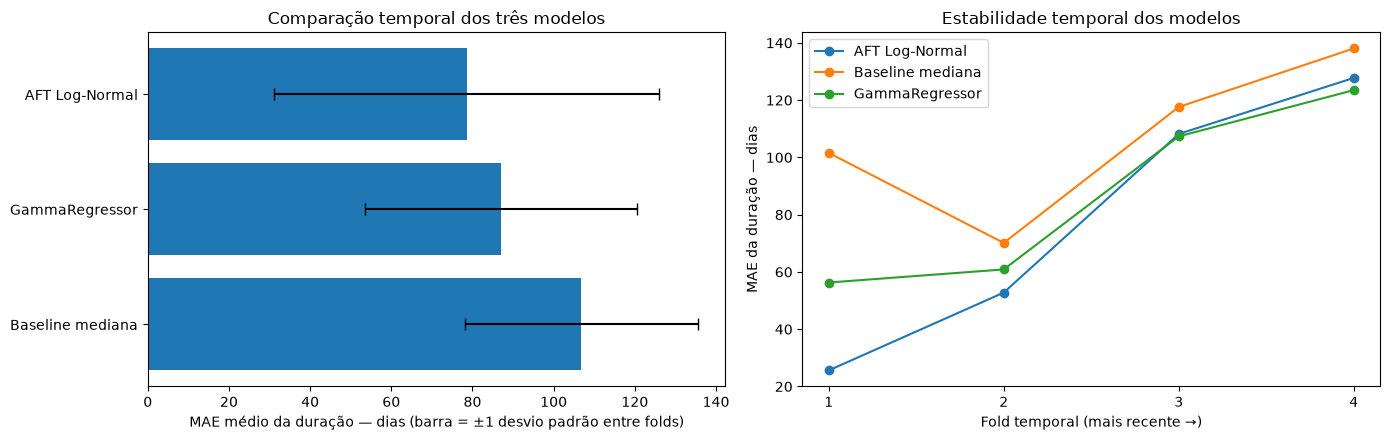

,fold,modelo,alpha,eventos_treino,concluidos_validacao,mae_duracao_dias,mae_relativo,cindex,cindex_censurado
0,1,Baseline mediana,NaN,23,7,101.571,0.391,0.500,0.500
1,1,GammaRegressor,0.1,23,7,56.304,0.290,0.738,0.738
2,1,AFT Log-Normal,1.0,23,7,25.610,0.190,0.738,0.738
3,2,Baseline mediana,NaN,28,6,70.125,0.308,0.500,0.500
4,2,GammaRegressor,0.1,28,6,60.870,0.558,0.800,0.800
5,2,AFT Log-Normal,1.0,28,6,52.785,0.411,0.800,0.800
6,3,Baseline mediana,NaN,31,5,117.600,0.756,0.500,0.500
7,3,GammaRegressor,0.1,31,5,107.333,0.762,0.500,0.393
8,3,AFT Log-Normal,1.0,31,5,108.178,0.745,0.500,0.393
9,4,Baseline mediana,NaN,41,4,138.052,1.141,0.500,0.500


In [10]:
resumo_modelos = (
    todos_cv.groupby(["modelo", "alpha"], dropna=False, as_index=False)
    .agg(
        mae_duracao_dias=("mae_duracao_dias", "mean"),
        mae_duracao_dp=("mae_duracao_dias", "std"),
        mae_relativo=("mae_relativo", "mean"),
        mae_estouro_original_dias=("mae_estouro_original_dias", "mean"),
        cindex_medio=("cindex", "mean"),
        cindex_censurado_medio=("cindex_censurado", "mean"),
        folds=("fold", "count"),
    )
)

# Melhor alpha de cada família, ordenado do melhor para o pior modelo.
melhor_por_familia = (
    resumo_modelos.sort_values("mae_duracao_dias")
    .drop_duplicates("modelo")
    .reset_index(drop=True)
)
display(melhor_por_familia.round(3))

# Resultados por fold, só na configuração vencedora de cada família.
comparacao_folds = todos_cv.merge(melhor_por_familia[["modelo", "alpha"]], on=["modelo", "alpha"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

ax1.barh(melhor_por_familia["modelo"], melhor_por_familia["mae_duracao_dias"],
         xerr=melhor_por_familia["mae_duracao_dp"], capsize=4)
ax1.invert_yaxis()
ax1.set_xlabel("MAE médio da duração — dias (barra = ±1 desvio padrão entre folds)")
ax1.set_title("Comparação temporal dos três modelos")

for nome, parte in comparacao_folds.groupby("modelo"):
    ax2.plot(parte["fold"], parte["mae_duracao_dias"], marker="o", label=nome)
ax2.set_xticks(comparacao_folds["fold"].unique())
ax2.set_xlabel("Fold temporal (mais recente →)")
ax2.set_ylabel("MAE da duração — dias")
ax2.set_title("Estabilidade temporal dos modelos")
ax2.legend()

plt.tight_layout()
plt.show()

display(comparacao_folds[["fold", "modelo", "alpha", "eventos_treino", "concluidos_validacao",
                          "mae_duracao_dias", "mae_relativo", "cindex", "cindex_censurado"]].round(3))

In [11]:
# Vencedor e ganho percentual entre as famílias.
melhor = melhor_por_familia.iloc[0]
BEST_MODEL, BEST_ALPHA = melhor["modelo"], melhor["alpha"]

mae = melhor_por_familia.set_index("modelo")["mae_duracao_dias"]
mae_baseline, mae_gamma, mae_aft = mae["Baseline mediana"], mae["GammaRegressor"], mae["AFT Log-Normal"]


def ganho(referencia, modelo):
    """Redução percentual do erro (positivo = modelo melhor que a referência)."""
    return 100 * (referencia - modelo) / referencia


ganho_gamma_vs_baseline = ganho(mae_baseline, mae_gamma)
ganho_aft_vs_baseline = ganho(mae_baseline, mae_aft)
ganho_aft_vs_gamma = ganho(mae_gamma, mae_aft)

print(f"Melhor modelo: {BEST_MODEL}" + (f" (alpha = {BEST_ALPHA})" if pd.notna(BEST_ALPHA) else ""))
print(f"MAE médio da duração: {melhor['mae_duracao_dias']:.2f} dias")
print(f"MAE relativo:         {melhor['mae_relativo']:.3f}")
print(f"C-index médio:        {melhor['cindex_medio']:.3f}")
print()
print(f"Baseline: {mae_baseline:.1f} dias | Gamma: {mae_gamma:.1f} dias | AFT: {mae_aft:.1f} dias")
print(f"Ganho Gamma vs baseline: {ganho_gamma_vs_baseline:+.1f}%")
print(f"Ganho AFT vs baseline:   {ganho_aft_vs_baseline:+.1f}%")
print(f"Ganho AFT vs Gamma:      {ganho_aft_vs_gamma:+.1f}%")

Melhor modelo: AFT Log-Normal (alpha = 1.0)
MAE médio da duração: 78.58 dias
MAE relativo:         0.614
C-index médio:        0.593

Baseline: 106.8 dias | Gamma: 87.0 dias | AFT: 78.6 dias
Ganho Gamma vs baseline: +18.6%
Ganho AFT vs baseline:   +26.4%
Ganho AFT vs Gamma:      +9.7%


In [12]:
previsoes_andamento = None

if BEST_MODEL == "AFT Log-Normal":
    # --- Ajuste final com todos os contratos aptos ---------------------------
    modelagem_final = df[df["flag_apto_modelagem"].eq(1)]
    andamento = df[df["grupo_modelagem"].eq("EM_ANDAMENTO_CENSURADO")].copy()

    prep_final, X_final, X_andamento = preprocessar(modelagem_final, andamento)
    modelo_final = LogNormalAFT(alpha=float(BEST_ALPHA)).fit(
        X_final, modelagem_final["tempo_relativo_observado"], modelagem_final["evento_conclusao"]
    )

    print(f"Modelo final: {BEST_MODEL} | eventos: {int(modelagem_final['evento_conclusao'].sum())} | "
          f"censurados: {int(modelagem_final['evento_conclusao'].eq(0).sum())} | "
          f"convergiu: {modelo_final.resultado_.success}")

    # --- Risco dos contratos em andamento -------------------------------------
    andamento["prob_ultrapassar_prazo_original"] = modelo_final.sobrevivencia(X_andamento, np.ones(len(andamento)))
    andamento["prob_ultrapassar_prazo_vigente_hoje"] = modelo_final.prob_exceder_limite_condicional(
        X_andamento, andamento["tempo_relativo_observado"], andamento["limite_relativo_vigente"]
    )
    andamento["duracao_mediana_estimada_dias"] = (
        modelo_final.mediana_tempo_relativo(X_andamento) * andamento["prazo_original_dias"]
    )

    previsoes_andamento = andamento[[
        "id_contrato", "classificacao_contrato", "prazo_original_dias", "prazo_vigente_atual_dias",
        "tempo_observado_dias", "tempo_relativo_observado", "limite_relativo_vigente",
        "prob_ultrapassar_prazo_original", "prob_ultrapassar_prazo_vigente_hoje",
        "duracao_mediana_estimada_dias",
    ]].sort_values("prob_ultrapassar_prazo_vigente_hoje", ascending=False)

    display(previsoes_andamento.round(3))
else:
    print(f"O AFT não venceu a validação (vencedor: {BEST_MODEL}).")
    print("Revise a comparação antes de usar as probabilidades de risco dos contratos em andamento.")

Modelo final: AFT Log-Normal | eventos: 50 | censurados: 13 | convergiu: True


,id_contrato,classificacao_contrato,prazo_original_dias,prazo_vigente_atual_dias,tempo_observado_dias,tempo_relativo_observado,limite_relativo_vigente,prob_ultrapassar_prazo_original,prob_ultrapassar_prazo_vigente_hoje,duracao_mediana_estimada_dias
51,376,Reforma Global,360,360.0,540,1.500,1.0,0.816,1.000,517.577
60,405,Reforma Parcial,180,180.0,413,2.294,1.0,0.871,1.000,284.559
38,271,Reforma Global,900,900.0,888,0.987,1.0,0.721,0.985,1141.025
41,275,Construção,1080,1080.0,877,0.812,1.0,0.700,0.823,1335.363
57,392,Reforma Parcial,540,540.0,362,0.670,1.0,0.777,0.809,734.357
48,340,Reforma Global e Ampliação,720,720.0,504,0.700,1.0,0.746,0.795,941.226
56,391,Construção,600,600.0,378,0.630,1.0,0.766,0.790,804.237
63,418,Reforma Global e Ampliação,660,660.0,92,0.139,1.0,0.756,0.756,873.161
58,398,Construção,720,720.0,320,0.444,1.0,0.746,0.749,941.226
55,390,Construção,1080,1080.0,344,0.319,1.0,0.700,0.701,1335.363
